# Engines: fastai

> bonsai training engines: fastai backend


In [1]:
#| default_exp engines.fastai

In [2]:
#| hide
from nbdev.showdoc import *
from fastcore.test import *

from bonsai.datasets import download_medmnist
from bonsai.optimizers import Adam

In [3]:
#| export

# =================================
# Standard library
# =================================

from __future__ import annotations

import inspect
from abc import ABC, abstractmethod
from dataclasses import dataclass, field
from typing import TYPE_CHECKING, Any, Callable, Dict, Mapping, Optional, Type
from pathlib import Path

# =================================
# Scientific / data
# =================================
import numpy as np
import pandas as pd

# =================================
# Visualization
# =================================
import matplotlib.pyplot as plt
plt.ion()
from matplotlib.colors import LinearSegmentedColormap

from contextlib import contextmanager

# =================================
# Imaging
# =================================
# from skimage import util

# =================================
# PyTorch
# =================================
import torch
import torch.optim as toptim
from torch.optim import Optimizer
from torch.cuda import is_available as is_cuda_available
from torch.nn.init import kaiming_normal_

# =================================
# MONAI
# =================================
from monai.engines.utils import (default_make_latent,
                                 default_metric_cmp_fn,
                                 default_prepare_batch
                                 )
from monai.handlers.utils import from_engine
from monai.handlers import IgniteMetricHandler
from monai.metrics import LossMetric
from monai.utils.enums import ForwardMode

# =================================
# fastai
# =================================
from fastai.callback.core import Callback
from fastai.callback.all import *

from fastai.data.all import (
    DataLoaders, Path, trainable_params, delegates,
    hasattrs, List, L, Normalize
)

from fastai.optimizer import OptimWrapper, Optimizer as fastaiOptimizer

from fastai.vision.all import (
    Any, BypassNewMeta, ClassificationInterpretation,
    DataBlock, DisplayedTransform, Learner,
    create_vision_model, create_timm_model, default_split,
    get_c, ifnone, minimum, model_meta, slide, steep, store_attr, valley
)

# =================================
# fastcore
# =================================
from fastcore.script import risinstance

# =================================
# bonsai
# =================================
from bonsai.backend import get_backend
from bonsai.optimizers import Adam
from bonsai.utils import *
from bonsai.callbacks import CSVLogger, MeanLossGraphCallback
from bonsai.visualize import teal_cmap
from bonsai.engines.core import *
from bonsai.engines.core import (_evaluation_metrics, _prediction_activation, _evaluation_detach, _monai_metric_config,
                                 _display_evaluation_statistics, _prediction_decode, _metric_prediction, _display_evaluation_outputs)

## fastai Engines

In [4]:
#| export

def _fastai_fit(
        self,
        n_epoch=None,
        lr=None,
        wd=None,
        cbs=None,
        reset_opt=False,
        start_epoch=0,
):
    """
    Train using the configured fastai trainer.

    The signature follows :meth:`fastTrainer.fit`, while arguments omitted
    by the caller are filled from the canonical :class:`TrainerConfig`.

    Parameters
    ----------
    n_epoch
        Number of epochs. If ``None``, uses ``config.epochs``.
    lr
        Learning rate. If ``None``, uses ``config.lr``.
    wd
        Weight decay. If ``None``, uses ``backend_kwargs["wd"]`` when
        provided; otherwise the native fastai default is used.
    cbs
        Callbacks passed to ``fastTrainer.fit``. If ``None``, uses
        ``config.callbacks``.
    reset_opt
        Whether to reset the optimizer before training.
    start_epoch
        Epoch from which to resume training.

    Returns
    -------
    Any
        Result returned by ``fastTrainer.fit``.
    """
    cfg = self.config

    if n_epoch is None:
        n_epoch = cfg.epochs

    if lr is None:
        lr = cfg.lr

    if cbs is None:
        cbs = cfg.callbacks

    if wd is None:
        wd = cfg.backend_kwargs.get("wd", None)

    return self.trainer.fit(
        n_epoch=n_epoch,
        lr=lr,
        wd=wd,
        cbs=cbs,
        reset_opt=reset_opt,
        start_epoch=start_epoch,
    )

In [5]:
#| export

def _fastai_evaluation_metric_value(metric, pred, target):
    """Evaluate one batch using the native fastai metric lifecycle."""
    from fastai.learner import Metric as FastaiMetric
    from types import SimpleNamespace
    from sklearn.metrics import average_precision_score, roc_auc_score

    with torch.no_grad():
        if isinstance(metric, FastaiMetric):
            if (getattr(metric, "func", None) is average_precision_score
                    and not metric.flatten and pred.ndim == 2 and target.ndim == 1):
                target = torch.nn.functional.one_hot(target, num_classes=pred.shape[1])
            metric.reset()
            learn = SimpleNamespace(pred=pred, y=target, yb=(target,), to_detach=_evaluation_detach)
            metric.accumulate(learn)
            try:
                value = metric.value
            except ValueError as exc:
                # ROC AUC is undefined when the evaluated batch omits classes.
                if getattr(metric, "func", None) is not roc_auc_score or str(exc) not in (
                    "Number of classes in y_true not equal to the number of columns in 'y_score'",
                    "Only one class present in y_true. ROC AUC score is not defined in that case.",
                ):
                    raise
                value = float("nan")
        else:
            if hasattr(metric, "reset"):
                metric.reset()
            value = metric(pred, target)
        return _evaluation_detach(value)

In [6]:
#| export

def _fastai_evaluate(
        self,
        dl=None,
        split: int | str = "val",
        with_input: bool = False,
        with_decoded: bool = False,
        with_loss: bool = True,
        act=None,
        inner: bool = False,
        reorder: bool = True,
        cbs=None,
        *,
        with_metrics: bool = True,
        metrics=None,
        show_stats: bool = True,
        show_results: bool = True,
        classification_report: bool = False,
        min_val: int = 1,
        n_most_confused: int | None = 5,
        save_preds=None,
        save_targs=None,
        save_report=None,
        with_preds: bool = True,
        with_targs: bool = True,
        max_n=9,
        cmap=teal_cmap,
        pickle_protocol: int = 2,
) -> dict:
    """
    Evaluate the model and optionally return predictions, targets, and inputs.

    Parameters
    ----------
    dl : DataLoader, optional
        Dataloader to use for evaluation. When provided, overrides ``split``.
    split : int or str, default="val"
        Dataset split to evaluate. Accepts ``0`` or ``"train"`` for the
        training set, and ``1`` or ``"val"`` for the validation set.
        Ignored when ``dl`` is provided.
    with_input : bool, default=False
        Whether to return inputs alongside predictions.
    with_decoded : bool, default=False
        Whether to return decoded predictions.
    with_loss : bool, default=True
        Whether to return one loss value per evaluation batch.
    act : callable, optional
        Activation function applied to predictions. Defaults to the
        activation configured by the loss function.
    inner : bool, default=False
        Whether to run prediction without the usual progress bar,
        logger, and temporary callbacks.
    reorder : bool, default=True
        Whether to restore predictions to dataset order when applicable.
    cbs : Callback or sequence of Callback, optional
        Temporary callbacks used during prediction.
    save_preds : Path, optional
        Path to save predictions.
    save_targs : Path, optional
        Path to save targets.
    save_report : path-like, optional
        Save the selected plots and tables as a multipage PDF. Requires
        a .pdf filename. Includes only output enabled by show_results,
        show_stats, and classification_report; notebook display is retained.
        Parent directories are created. An existing report is replaced
        only after all visual output has been saved successfully.
    with_preds : bool, default=True
        Whether to return predictions.
    with_targs : bool, default=True
        Whether to return targets.
    pickle_protocol : int, default=2
        Pickle protocol used when saving predictions and targets.
    with_metrics : bool, default=True
        Compute metrics independently for every evaluation batch.
    metrics : callable, sequence, or mapping, optional
        Metrics to compute when with_metrics is True. Defaults to metrics
        attached to the evaluator (the Learner for fastai). A mapping supplies
        explicit metric names. An empty collection disables all metrics.
    show_stats : bool, default=True
        Show one plot_stats plot and one display_statistics_table table for
        each collected loss and metric (enabled by with_loss/with_metrics).
        Non-finite values are excluded from displays only; empty distributions
        are skipped with a warning. KDE is disabled for constant values.
    show_results : bool, default=True
        Call the backend's show_results(max_n=max_n) after evaluation.
        This performs a separate display pass; dl and split are not
        forwarded, and collected inputs or predictions are not reused.
    max_n : int, default=9
        Maximum samples in the separate show_results display. Does not
        limit evaluation or the number of returned samples.
    min_val : int, default=1
        Minimum count for a class pair in the most-confused table.
        Used only when classification_report=True.
    n_most_confused : int or None, default=5
        Maximum class pairs in the most-confused table, sorted by descending
        count. None includes all pairs meeting min_val. Used only when
        classification_report=True; does not limit evaluated samples.
    classification_report : bool, default=False
        Show a confusion matrix, most-confused classes, and sklearn
        classification report. Adds computed diagnostics under
        result["classification_report"]. Supports single-label classification;
        use act to convert binary logits to probabilities.

    Returns
    -------
    dict
        "losses" contains one scalar per evaluation batch. With with_metrics=True,
        "metrics" maps names to lists of per-batch values, in inference order,
        independently of prediction reordering. ROC AUC is NaN for batches
        missing required classes. Metrics and losses receive raw model outputs;
        returned predictions and decoded outputs use the requested activation.
        Requested outputs keyed by ``preds``, ``targs``, ``inputs``,
        ``decoded``, and ``losses``. Disabled outputs are omitted.
        Decoded predictions are omitted when predictions are unavailable.

    Raises
    ------
    ValueError
        If ``split`` is not a supported index or name.
    RuntimeError
        If the trainer does not expose ``get_preds()``.
    """
    if not hasattr(self.trainer, "get_preds"):
        raise RuntimeError(
            f"Trainer {type(self.trainer).__name__!r} does not provide "
            "a prediction interface compatible with fastai."
        )

    if dl is None:
        if isinstance(split, str):
            splits = {"train": 0, "val": 1, "valid": 1}
            try:
                split = splits[split.lower()]
            except KeyError:
                raise ValueError(
                    f"Invalid split {split!r}. Use 'train', 'val', "
                    "0, or 1."
                ) from None
        elif split not in (0, 1) or isinstance(split, bool):
            raise ValueError(
                f"Invalid split {split!r}. Use 'train', 'val', 0, or 1."
            )

    metric_fns = _evaluation_metrics(
        self.trainer.metrics if metrics is None else metrics
    ) if with_metrics else {}

    result = {}
    if with_loss:
        result["losses"] = []
    if with_metrics:
        result["metrics"] = {name: [] for name in metric_fns}

    class CollectBatchStatistics(Callback):
        def after_batch(cb):
            pred, target = cb.learn.pred, cb.learn.y
            with torch.no_grad():
                if with_loss:
                    result["losses"].extend(
                        compute_losses(pred, target, self.trainer.loss_func, batch_size=len(target))
                    )
                for name, metric in metric_fns.items():
                    result["metrics"][name].extend(
                        compute_metric(
                            pred, target,
                            lambda p, y: _fastai_evaluation_metric_value(metric, p, y),
                            batch_size=len(target),
                        )
                    )

    prediction_cbs = L(cbs)
    if with_loss or with_metrics:
        prediction_cbs = prediction_cbs + [CollectBatchStatistics()]

    outputs = self.trainer.get_preds(
        ds_idx=split,
        dl=dl,
        with_input=with_input,
        with_decoded=with_decoded,
        with_loss=False,
        act=act,
        inner=inner,
        reorder=reorder,
        cbs=prediction_cbs,
        save_preds=save_preds,
        save_targs=save_targs,
        with_preds=with_preds or classification_report,
        with_targs=with_targs or classification_report,
        pickle_protocol=pickle_protocol,
    )
    values = iter(outputs)
    if with_input:
        result["inputs"] = next(values)
    preds, targs = next(values), next(values)
    if with_preds:
        result["preds"] = preds
    if with_targs:
        result["targs"] = targs
    if with_decoded and preds is not None:
        result["decoded"] = next(values)
    _display_evaluation_outputs(
        result, (lambda: self.show_results(max_n=max_n)) if show_results else None,
        show_stats, classification_report, save_report,
        report_data=dict(result, preds=preds, targs=targs), cmap=cmap,
        min_val=min_val, n_most_confused=n_most_confused,
    )

    return result

In [7]:
#| hide
def test_fastai_evaluate_undefined_auc():
    from types import SimpleNamespace
    from unittest.mock import Mock
    from fastai.metrics import AccumMetric, APScoreBinary, APScoreMulti, RocAuc, RocAucBinary, accuracy
    from fastai.losses import CrossEntropyLossFlat
    from sklearn.metrics import average_precision_score, roc_auc_score

    logits = torch.tensor([[3., 1., 0.], [0., 3., 1.], [1., 0., 3.]])
    targets = torch.tensor([0, 1, 2])
    metric = RocAuc()
    for i in range(3):
        assert np.isnan(_fastai_evaluation_metric_value(metric, logits[i:i+1], targets[i:i+1]))
    assert np.isnan(_fastai_evaluation_metric_value(metric, logits[:2], targets[:2]))
    expected = roc_auc_score(targets.numpy(), logits.softmax(-1).numpy(), multi_class="ovr")
    assert _fastai_evaluation_metric_value(metric, logits, targets) == expected == 1.
    binary_logits = torch.tensor([[3., 1.], [1., 3.]])
    assert _fastai_evaluation_metric_value(RocAucBinary(), binary_logits, targets[:2]) == 1.

    assert _fastai_evaluation_metric_value(APScoreBinary(), binary_logits, targets[:2]) == 1.
    for labels in (targets, torch.nn.functional.one_hot(targets, 3)):
        expected = average_precision_score(
            torch.nn.functional.one_hot(targets, 3).numpy(), logits.sigmoid().numpy())
        assert _fastai_evaluation_metric_value(APScoreMulti(), logits, labels) == expected == 1.

    invalid = RocAuc()
    invalid.kwargs["multi_class"] = "invalid"
    test_fail(lambda: _fastai_evaluation_metric_value(invalid, logits, targets),
              contains="multi_class")
    def broken(pred, target):
        raise ValueError("Number of classes in y_true not equal to the number of columns in 'y_score'")
    test_fail(lambda: _fastai_evaluation_metric_value(AccumMetric(broken, flatten=False), logits, targets),
              contains="Number of classes")

    from fastai.data.load import DataLoader as FastaiDataLoader
    from fastai.data.core import DataLoaders
    from fastai.learner import Learner
    from monai.data import MetaTensor
    from torch.utils.data import TensorDataset

    for device in ["cpu"] + (["cuda"] if torch.cuda.is_available() else []):
        dl = FastaiDataLoader(TensorDataset(MetaTensor(logits), targets), bs=3, device=device)
        model = torch.nn.Linear(3, 3, bias=False).to(device)
        with torch.no_grad():
            model.weight.copy_(torch.eye(3, device=device))
        loss = CrossEntropyLossFlat()
        learn = Learner(DataLoaders(dl, dl, device=device), model, loss_func=loss,
                        metrics=[RocAuc(), accuracy])
        backend = SimpleNamespace(trainer=learn)
        callbacks = list(learn.cbs)
        result = _fastai_evaluate(backend, show_stats=False, show_results=False,
                                 with_decoded=True)
        assert result["metrics"] == {"roc_auc_score": [1.], "accuracy": [1.]}
        torch.testing.assert_close(result["preds"].cpu(), logits.softmax(-1))
        torch.testing.assert_close(result["targs"].cpu(), targets)
        torch.testing.assert_close(result["decoded"].cpu(), targets)
        torch.testing.assert_close(torch.tensor(result["losses"]), loss(logits, targets).reshape(1))
        assert list(learn.cbs) == callbacks


test_fastai_evaluate_undefined_auc()

In [8]:
#| hide
def test_fastai_evaluate_display_options():
    from types import SimpleNamespace
    from unittest.mock import Mock, patch

    inputs = torch.zeros(2, 1, 4, 4)
    preds = torch.tensor([[0.8, 0.2], [0.1, 0.9]])
    targs = torch.tensor([0, 1])
    decoded = torch.tensor([0, 1])
    losses = torch.tensor([0.2, 0.1])
    for options in ({}, {"show_stats": False, "show_results": False},
                    {"show_stats": True, "show_results": False},
                    {"show_stats": False, "show_results": True}):
        native = SimpleNamespace(get_preds=Mock(return_value=(inputs, preds, targs, decoded)))
        backend = SimpleNamespace(trainer=native, show_results=Mock())
        stats = Mock()
        with patch.dict(_fastai_evaluate.__globals__, {"display_evaluation_statistics": stats}):
            result = _fastai_evaluate(
                backend, with_input=True, with_decoded=True, with_loss=False, max_n=3, with_metrics=False, **options,
            )
        test_eq(backend.show_results.call_count, int(options.get("show_results", True)))
        if options.get("show_results", True):
            backend.show_results.assert_called_once_with(max_n=3)
        for key, value in (("inputs", inputs), ("preds", preds), ("targs", targs),
                           ("decoded", decoded)):
            test_eq(result[key], value)
        test_eq("show_stats" in native.get_preds.call_args.kwargs, False)
        test_eq("show_results" in native.get_preds.call_args.kwargs, False)

test_fastai_evaluate_display_options()

In [9]:
#| export

def _fastai_predict(self, *args, **kwargs):
    """
    Run inference using the configured fastai trainer.

    Parameters
    ----------
    *args
        Positional arguments passed to the trainer.
    **kwargs
        Keyword arguments passed to the trainer.

    Returns
    -------
    Any
        Prediction result returned by the trainer.
    """
    if not hasattr(self.trainer, "predict"):
        raise RuntimeError(
            f"Trainer {type(self.trainer).__name__!r} does not provide "
            "a prediction interface."
        )

    return self.trainer.get_preds(*args, **kwargs)

In [10]:
#| export
@register_backend("fastai")
class FastaiTrainerBackend(TrainerBackend):
    """
    fastai training backend for bonsai.

    This backend adapts the backend-independent :class:`TrainerConfig`
    interface to bonsai's fastai-based training implementations.

    The trainer implementation is selected through ``config.trainer`` and
    resolved from ``TRAINER_REGISTRY["fastai"]``. For example::

        BioTrainer(
            model=model,
            dls=dls,
            backend="fastai",
            trainer="supervised",
        )

    resolves the ``"supervised"`` trainer registered for the fastai backend.

    Notes
    -----
    The registered trainer is expected to be a bonsai trainer such as
    ``fastTrainer`` rather than a native fastai ``Learner``.
    """

    def _native_config(self) -> Dict[str, Any]:
        cfg = self.config

        return {
            "dataloaders": cfg.dls,
            "model": cfg.model,
            "loss_fn": cfg.loss,
            "optimizer": cfg.optimizer,
            "lr": cfg.lr,
            "callbacks": cfg.callbacks,
            "metrics": cfg.metrics,
            "cvs_log": cfg.csv_logger,
            "show_graph": cfg.show_graph,
            "show_summary": cfg.show_summary,
            "model_dir": cfg.save_dir,
            **cfg.backend_kwargs,
        }

    @property
    def recorder(self):
        return self.trainer.recorder


FastaiTrainerBackend.fit = _fastai_fit
FastaiTrainerBackend.evaluate = _fastai_evaluate
FastaiTrainerBackend.predict = _fastai_predict

FastTrainer is used for training models in bioinformatics applications, where specific loss functions and optimizers oriented to biological data can be used.

In [11]:
#| export
@register_trainer("fastai", "supervised")
class fastTrainer(Learner):
    """
    A custom implementation of the FastAI Learner class for training models in bioinformatics applications.

    """

    def __init__(self,
                 dataloaders: DataLoaders = None,  # The DataLoader objects containing training and validation datasets.
                 model: callable = None,  # A callable model that will be trained on the dataset.
                 loss_fn: Any | None = None,
                 # The loss function to optimize during training. If None, defaults to a suitable default.
                 optimizer: fastaiOptimizer | OptimWrapper = Adam,
                 # The optimizer function to use. Defaults to Adam if not specified.
                 lr: float | slice = 1e-3,
                 # Learning rate for the optimizer. Can be a float or a slice object for learning rate scheduling.
                 splitter: callable = trainable_params,  #
                 callbacks: Callback | MutableSequence | None = None,
                 # A callable that determines which parameters of the model should be updated during training.
                 metrics: Any | MutableSequence | None = None,
                 # Optional list of callback functions to customize training behavior.
                 csv_log: bool = False,  # Metrics to evaluate the performance of the model during training.
                 show_graph: bool = True,
                 # Whether to log training history to a CSV file. If True, logs will be appended to 'history.csv'.
                 show_summary: bool = True,
                 # The base directory where models are saved or loaded from. Defaults to None.
                 find_lr: bool = False,
                 # Subdirectory within the base path where trained models are stored. Default is 'models'.
                 find_lr_fn=valley,  # Weight decay factor for optimization. Defaults to None.
                 path: str | Path | None = None,
                 # Whether to apply weight decay to batch normalization and bias parameters.
                 model_dir: str | Path = 'models',
                 # Whether to update the batch normalization statistics during training.
                 wd: float | int | None = None,
                 wd_bn_bias: bool = False,
                 train_bn: bool = True,
                 moms: tuple = (0.95, 0.85, 0.95),
                 # Tuple of tuples representing the momentum values for different layers in the model. Defaults to FastAI's default settings if not specified.
                 default_cbs: bool = True,
                 # Automatically include default callbacks such as ShowGraphCallback and CSVLogger.
                 ):
        cbs = callbacks if callbacks is not None else []  # Ensure cbs is a list
        if default_cbs:
            if show_graph:
                cbs.append(MeanLossGraphCallback())
            if csv_log:
                cbs.append(CSVLogger(fname='history.csv', append=False))

        super().__init__(dataloaders, model, loss_fn, optimizer, lr, splitter, cbs, metrics, path, model_dir, wd,
                         wd_bn_bias, train_bn, moms)

        if show_summary:
            print(self.summary())
        if find_lr:
            lr = self.lr_find(suggest_funcs=find_lr_fn)
            self.lr = float('%.1g' % (lr))
            print('Inferred learning rate: ', self.lr)

    @classmethod
    def from_yaml(cls, dataloaders, model, yaml_path):
        """
        Method to read from a YAML file and obtain the parameters for FastTrainer.
        """
        # Read the configuration from the yaml file and replace None strings with Nonetype values
        config = read_yaml(yaml_path)
        config = {key: (None if value == "None" else value) for key, value in config.items()}

        # OBTAIN THE LOSS FUNCTION
        loss_str = config.get('loss_fn', None)
        # Look for the loss function within the variables and check if its valid
        if loss_str == None:
            loss_func = None
        else:
            lf_cls = globals().get(loss_str) or getattr(fm, loss_str, None)
            if lf_cls is None:
                raise ValueError(f"Loss function '{loss_str}' not found or invalid.")
            loss_func = lf_cls()

        # OBTAIN THE OPTIMIZER
        opt_str = config.get('optimizer', 'Adam')
        # Look for the optimizer within the variables and check if its valid
        if isinstance(opt_str, str):
            opt_cls = globals().get(opt_str, None)
            if opt_cls is None and hasattr(fastai.optimizer, opt_str):
                opt_cls = getattr(fastai.optimizer, opt_str)
            if opt_cls is None and hasattr(toptim, opt_str):
                opt_cls = getattr(toptim, opt_str)
            if opt_cls is None or not callable(opt_cls):
                raise ValueError(f"Optimizer '{opt_str}' not found or invalid.")
            opt_func = opt_cls

        # OBTAIN THE METRICS
        metrics_cfg = config.get('metrics', [])
        # Look for the metrics within the variables and check if they are valid
        valid_metrics = []
        if metrics_cfg == None:
            valid_metrics = None
        else:
            valid_metrics = dictlist_to_funclist(metrics_cfg)

        # OBTAIN THE CALLBACKS
        callbacks = []
        cbs = config.get('callbacks', [])
        callbacks = dictlist_to_funclist(cbs)

        # OBTAIN THE SPLITTER
        splitter_str = config.get('splitter', trainable_params)
        if isinstance(splitter_str, str):
            splitter_func = globals().get(splitter_str) or getattr(fastai.learner, splitter_str, None)
        elif splitter_str is None:
            splitter_func = trainable_params
        else:
            splitter_func = splitter_str

        # OBTAIN OTHER PARAMETERS FROM THE YAML CONFIGURATION
        lr = config.get('lr', 1e-3)
        csv_log = config.get('csv_log', False)
        show_graph = config.get('show_graph', True)
        show_summary = config.get('show_summary', False)
        path = config.get('path', None)
        model_dir = config.get('model_dir', 'models')
        wd = config.get('wd', None)
        wd_bn_bias = config.get('wd_bn_bias', False)
        train_bn = config.get('train_bn', True)
        moms = config.get('moms', (0.95, 0.85, 0.95))

        # Return all the parameters
        return cls(dataloaders=dataloaders, model=model, loss_fn=loss_func, optimizer=opt_func,
                   lr=lr, splitter=splitter_func, callbacks=callbacks, metrics=valid_metrics, path=path,
                   model_dir=model_dir, wd=wd, wd_bn_bias=wd_bn_bias, train_bn=train_bn, moms=moms,
                   csv_log=csv_log, show_graph=show_graph, show_summary=show_summary
                   )

#### Example: train a simple model.

In [12]:
from bonsai.data import BioDataLoaders, get_parent, BioImage, BioLabel, BioOneHot
from bonsai.metrics import ROCAUCMetric, AveragePrecisionMetric, AccuracyMetric
from bonsai.losses import CrossEntropyLoss
from bonsai.backend import set_backend
from torch import nn, flatten as torchflatten
from fastai.metrics import accuracy

In [13]:
set_backend('fastai')

'fastai'

In [14]:
# Import the data
image_path = '_data'
info = download_medmnist('bloodmnist', image_path, download_only=True)
batch_size = 32
path = Path(image_path) / 'bloodmnist'
path_train = path / 'train'
path_val = path / 'val'

Dataset 'bloodmnist' is already downloaded and available in '_data/bloodmnist'.


In [15]:
# Build BioDataLoaders
dls = BioDataLoaders.create(
    x_class=BioImage,
    y_class=BioLabel,
    data=path_train,
    val_data=path_val,
    task="classification",
    dataset="dataset",
    get_items={"image": ".", "label": get_parent},
    batch_size=batch_size,
)

In [16]:
# Small CNN for the integration test
class TestCNN(nn.Module):
    def __init__(self, n_classes=8):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d(1),
        )

        self.classifier = nn.Linear(32, n_classes)

    def forward(self, x):
        x = self.features(x)
        x = torchflatten(x, 1)
        return self.classifier(x)


model = TestCNN(n_classes=8)

In [17]:
# Create the backend-independent trainer
trainer = BioTrainer(
    model=model,
    dls=dls,
    optimizer=Adam,
    metrics=[ROCAUCMetric, AveragePrecisionMetric, AccuracyMetric],
    loss=CrossEntropyLoss,
    epochs=1,
    lr=1e-3,
    validate=True,
    show_summary=True,
    show_graph=True,
)

TestCNN (Input shape: 32 x 3 x 28 x 28)
Layer (type)         Output Shape         Param #    Trainable 
                     32 x 16 x 28 x 28   
Conv2d                                    448        True      
ReLU                                                           
____________________________________________________________________________
                     32 x 16 x 14 x 14   
MaxPool2d                                                      
____________________________________________________________________________
                     32 x 32 x 14 x 14   
Conv2d                                    4640       True      
ReLU                                                           
____________________________________________________________________________
                     32 x 32 x 1 x 1     
AdaptiveAvgPool2d                                              
____________________________________________________________________________
                     32 x 8         

epoch,train_loss,valid_loss,roc_auc_score,average_precision_score,__fastai_accuracy,time
0,1.614959,1.556047,0.811075,0.357130,0.380841,00:21


/home/bm/Documents/bonsai/bonsai/callbacks.py:413: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


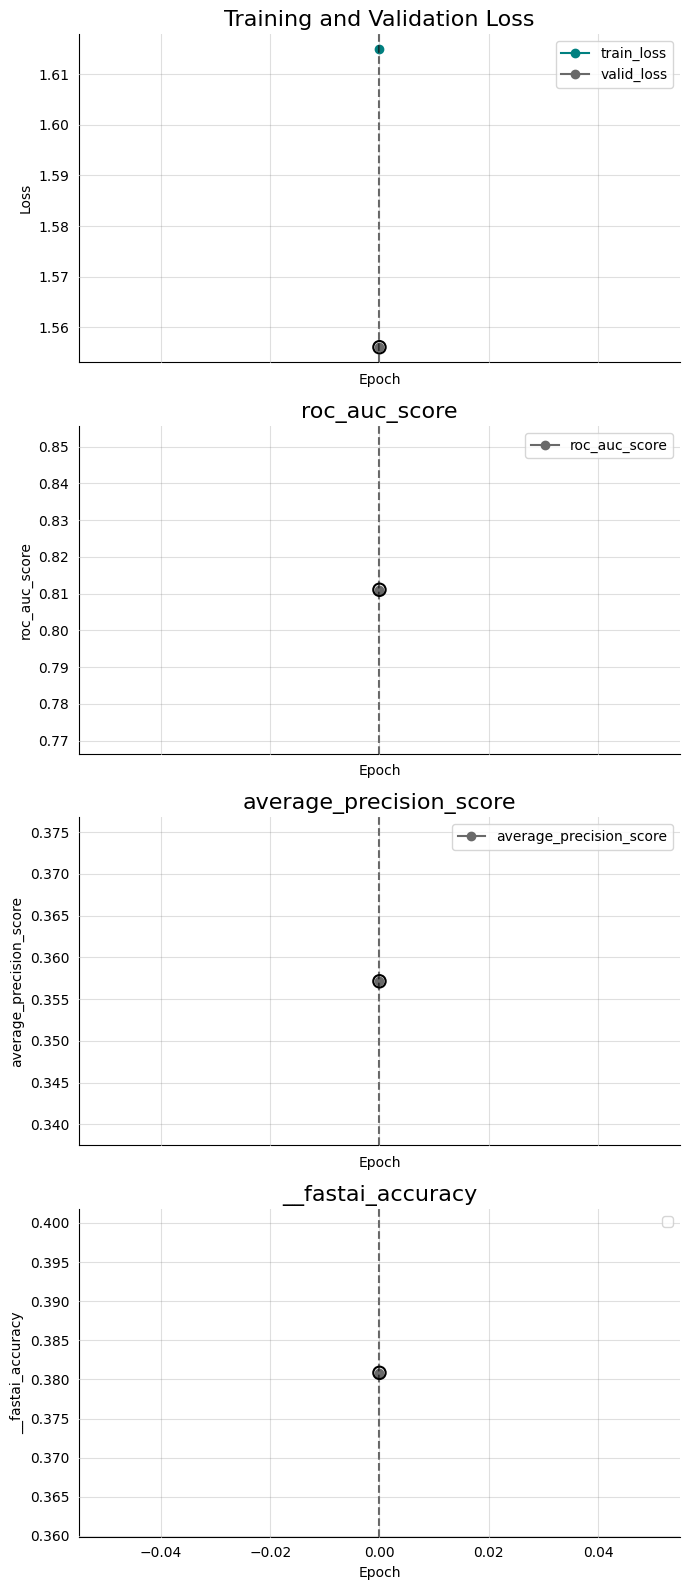

In [18]:
# Train
trainer.fit()

In [19]:
trainer.evaluate(show_results=True, classification_report=True);

/home/bm/miniforge3/envs/bonsai-latest-ignite/lib/python3.11/site-packages/sklearn/metrics/_ranking.py:1131: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/home/bm/miniforge3/envs/bonsai-latest-ignite/lib/python3.11/site-packages/sklearn/metrics/_ranking.py:1131: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/home/bm/miniforge3/envs/bonsai-latest-ignite/lib/python3.11/site-packages/sklearn/metrics/_ranking.py:1131: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/home/bm/miniforge3/envs/bonsai-latest-ignite/lib/python3.11/site-packages/sklearn/metrics/_ranking.py:1131: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/home/bm/miniforge3/envs/bonsai-latest-ignite/lib/python3.11/site-packages/sklearn/metrics/_ranking.py:1131: UserWarning: No positive class 

ValueError: Exception occured in `Recorder` when calling event `after_validate`:
	Number of classes in y_true not equal to the number of columns in 'y_score'

### Vision Trainer

---

In [ ]:
#| export
def _add_norm(dls, meta, pretrained, n_in=3):
    if not pretrained: return
    stats = meta.get('stats')
    if stats is None: return
    if n_in != len(stats[0]): return
    if not dls.after_batch.fs.filter(risinstance(Normalize)):
        dls.add_tfms([Normalize.from_stats(*stats)], 'after_batch')


def _timm_norm(dls, cfg, pretrained, n_in=3):
    if not pretrained: return
    if n_in != len(cfg['mean']): return
    if not dls.after_batch.fs.filter(risinstance(Normalize)):
        tfm = Normalize.from_stats(cfg['mean'], cfg['std'])
        dls.add_tfms([tfm], 'after_batch')

VisionTrainer is used for computer vision applications, where image normalization or other computer vision related settings are needed.

In [ ]:
#| export
@register_trainer("fastai", "vision")
@delegates(create_vision_model)
def visionTrainer(dataloaders: DataLoaders,  # The DataLoader objects containing training and validation datasets.
                  model: callable,  # A callable model that will be trained on the dataset.
                  normalize=True,
                  n_out=None,
                  pretrained=True,
                  weights=None,
                  # Trainer args
                  loss_fn: Any | None = None,
                  # The loss function to optimize during training. If None, defaults to a suitable default.
                  optimizer: fastaiOptimizer | OptimWrapper = Adam,
                  # The optimizer function to use. Defaults to Adam if not specified.
                  lr: float | slice = 1e-3,
                  # Learning rate for the optimizer. Can be a float or a slice object for learning rate scheduling.
                  splitter: callable = trainable_params,  #
                  callbacks: Callback | MutableSequence | None = None,
                  # A callable that determines which parameters of the model should be updated during training.
                  metrics: Any | MutableSequence | None = None,
                  # Optional list of callback functions to customize training behavior.
                  csv_log: bool = False,  # Metrics to evaluate the performance of the model during training.
                  show_graph: bool = True,
                  # Whether to log training history to a CSV file. If True, logs will be appended to 'history.csv'.
                  show_summary: bool = False,
                  # The base directory where models are saved or loaded from. Defaults to None.
                  find_lr: bool = False,
                  # Subdirectory within the base path where trained models are stored. Default is 'models'.
                  find_lr_fn=valley,  # Weight decay factor for optimization. Defaults to None.
                  path: str | Path | None = None,
                  # Whether to apply weight decay to batch normalization and bias parameters.
                  model_dir: str | Path = 'models',
                  # Whether to update the batch normalization statistics during training.
                  wd: float | int | None = None,
                  wd_bn_bias: bool = False,
                  train_bn: bool = True,
                  moms: tuple = (0.95, 0.85, 0.95),
                  # Tuple of tuples representing the momentum values for different layers in the model. Defaults to FastAI's default settings if not specified.
                  default_cbs: bool = True,
                  # Automatically include default callbacks such as ShowGraphCallback and CSVLogger.
                  # model & head args
                  cut=None,
                  init=kaiming_normal_,
                  custom_head=None,
                  concat_pool=True,
                  pool=True,
                  lin_ftrs=None,
                  ps=0.5,
                  first_bn=True,
                  bn_final=False,
                  lin_first=False,
                  y_range=None,
                  **kwargs):
    """Build a vision trainer from `dataloaders` and `model`"""
    if n_out is None: n_out = get_c(dataloaders)
    assert n_out, "`n_out` is not defined, and could not be inferred from data, set `dataloaders.c` or pass `n_out`"
    meta = model_meta.get(model, {'cut': cut, 'split': default_split})
    model_args = dict(init=init, custom_head=custom_head, concat_pool=concat_pool, pool=pool, lin_ftrs=lin_ftrs, ps=ps,
                      first_bn=first_bn, bn_final=bn_final, lin_first=lin_first, y_range=y_range, **kwargs)
    n_in = kwargs['n_in'] if 'n_in' in kwargs else 3
    if isinstance(model, str):
        model, cfg = create_timm_model(model, n_out, default_split, pretrained, **model_args)
        if normalize: _timm_norm(dataloaders, cfg, pretrained, n_in)
    else:
        if normalize: _add_norm(dataloaders, meta, pretrained, n_in)
        model = create_vision_model(model, n_out, pretrained=pretrained, weights=weights, **model_args)

    splitter = ifnone(splitter, meta['split'])
    trainer = fastTrainer(dataloaders, model, loss_fn=loss_fn, optimizer=optimizer, lr=lr, splitter=splitter,
                          callbacks=callbacks, csv_log=csv_log,
                          show_graph=show_graph, show_summary=show_summary, find_lr=find_lr, find_lr_fn=find_lr_fn,
                          metrics=metrics, path=path,
                          model_dir=model_dir, wd=wd, wd_bn_bias=wd_bn_bias, train_bn=train_bn, moms=moms,
                          default_cbs=default_cbs)
    if pretrained: trainer.freeze()
    # keep track of args for loggers
    store_attr('model,normalize,n_out,pretrained', self=trainer, **kwargs)
    return trainer

In [ ]:
#| hide
import nbdev;

nbdev.nbdev_export()